# RL Robotic arm

In [ ]:
!pip install -q "gymnasium[mujoco]" mujoco imageio imageio-ffmpeg matplotlib

import os
os.environ["MUJOCO_GL"] = "egl"

import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Normal
import numpy as np
import imageio
import matplotlib.pyplot as plt

In [ ]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

#environment setup
train_env=gym.make("Pusher-v5")
action_size=train_env.action_space.shape[0]
state_size=train_env.observation_space.shape[0]
obs_dim=state_size
act_dim=action_size
features=23

#rollout and batching hyperparameters
total_timesteps=500000
buffer_size=2048
num_mb=32
epochs=10

#core ppo and gae hyperparameters
gamma=0.99
gae_lambda=0.95
clip_coef=0.2
c1_vf_coef=0.5
c2_ent_coef =0.0
max_grad_norm=0.5

#code-level ablation toggles
use_obs_norm=True
use_ortho_init =True

#two-timescale step-size schedule
lr_actor=3e-4
lr_critic=3e-4
use_two_timescale=False
actor_decay_exp=0.85
critic_decay_exp=0.60
timescale_c=0.05

#logging and plotting setup
window_size=50
loss_history=[]
reward_history=[]
critic_mse_history=[]

In [ ]:
def init_weights(module, std=np.sqrt(2), bias_const=0.0):
  if isinstance(module, nn.Linear):
    nn.init.orthogonal_(module.weight, std)
    nn.init.constant_(module.bias, bias_const)

In [ ]:
#class actor
class Actor(nn.Module):

  def __init__(self, use_ortho_init=True):

    super().__init__()

    #defining the actor network that takes in input features and output will be torques in the joints

    self.act=nn.Sequential(
        nn.Linear(23, 64),
        nn.Tanh(),
        nn.Linear(64, 64),
        nn.Tanh(),
        nn.Linear(64, 7)
    ).to(device)

    self.log_std=nn.Parameter(torch.full((7,), -0.5, device=device))

    if use_ortho_init:
      self.act.apply(lambda m: init_weights(m, std=np.sqrt(2)))
      init_weights(self.act[-1], std=0.01)

  def forward(self, x):
    mean=self.act(x)
    std=torch.exp(self.log_std.expand_as(mean))
    return mean, std

In [ ]:
#critic class
class Critic(nn.Module):

  def __init__(self, use_ortho_init=True):

    super().__init__()

    #defining the critic network that takes in input features and output will be value of the input state

    self.crit=nn.Sequential(
        nn.Linear(23, 64),
        nn.Tanh(),
        nn.Linear(64, 64),
        nn.Tanh(),
        nn.Linear(64, 1)
    ).to(device)

    if use_ortho_init:
      self.crit.apply(lambda m: init_weights(m, std=np.sqrt(2)))
      init_weights(self.crit[-1], std=1.0)

  def forward(self, x):
      out=self.crit(x)
      return out.squeeze(-1)

In [ ]:
def reset_nets(use_ortho_init=True):
  actor=Actor(use_ortho_init=use_ortho_init).to(device)
  critic=Critic(use_ortho_init=use_ortho_init).to(device)
  optimizer=torch.optim.Adam([
      {'params': actor.act.parameters(), 'lr': lr_actor},
      {'params': critic.crit.parameters(), 'lr': lr_critic},
      {'params': [actor.log_std], 'lr': lr_actor}
  ], eps=1e-5)
  return actor, critic, optimizer

In [ ]:
def gae_returns(rewards, values, next_values, terminateds, dones, gamma, gae_lambda):

  advantages=torch.zeros_like(rewards)
  returns=torch.zeros_like(rewards)
  last_gae=0.0

  for i in reversed(range(buffer_size)):
    delta=rewards[i]+gamma*next_values[i]*(1-terminateds[i])-values[i]
    last_gae=delta+gamma*gae_lambda*(1-dones[i])*last_gae
    advantages[i]=last_gae

  returns=advantages+values
  return advantages, returns

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

def update_nets(states, actions, log_prob_old, returns, gae, use_adv_norm=True, cur_clip_coef=0.2):
  mb_size=buffer_size//num_mb

  if use_adv_norm:
    gae=(gae-gae.mean())/(gae.std()+1e-8)

  #making mini-batches
  dataset=TensorDataset(states, actions, log_prob_old, returns, gae)
  dataloader=DataLoader(dataset, batch_size=mb_size, shuffle=True)

  batch_losses=[]
  batch_critic_mses=[]

  for epoch in range(epochs):
    for mb_state, mb_action, mb_log_prob_old, mb_returns, mb_gae in dataloader:
      #evaluate current policy distribution on mini-batch states

      mean, std=actor(mb_state)
      dist=Normal(mean, std)

      #sum log_prob and entropy across all 7 continuous action dimensions
      mb_log_prob_new=dist.log_prob(mb_action).sum(dim=-1)
      entropy=dist.entropy().sum(dim=-1).mean()

      #importance sampling ratio pi_new(a|s) / pi_old(a|s)
      ratio=torch.exp(mb_log_prob_new - mb_log_prob_old)

      #clipped surrogate actor objective
      surr1=ratio*mb_gae
      surr2=torch.clamp(ratio, 1.0 - cur_clip_coef, 1.0 + cur_clip_coef) * mb_gae
      actor_loss=-torch.min(surr1, surr2).mean()

      #unclipped mse loss for critic value predictions
      values_pred=critic(mb_state)
      critic_loss=nn.functional.mse_loss(values_pred, mb_returns)

      #combined ppo objective
      total_loss=actor_loss+c1_vf_coef*critic_loss-c2_ent_coef*entropy

      optimizer.zero_grad()
      total_loss.backward()

      #clip gradient norms on actor and critic to prevent exploding updates
      torch.nn.utils.clip_grad_norm_(actor.parameters(), max_grad_norm)
      torch.nn.utils.clip_grad_norm_(critic.parameters(), max_grad_norm)
      optimizer.step()

      batch_losses.append(total_loss.item())
      batch_critic_mses.append(critic_loss.item())

  #recording for plotting
  loss_history.append(np.mean(batch_losses))
  critic_mse_history.append(np.mean(batch_critic_mses))

In [ ]:
#initialize networks, running observation/return stats and lists
actor, critic, optimizer=reset_nets()
obs_mean=np.zeros(obs_dim, dtype=np.float64)
obs_var=np.ones(obs_dim, dtype=np.float64)
obs_count=1e-4
ret_mean=0.0
ret_var=1.0
ret_count=1e-4
running_ret=0.0
reward_history=[]
loss_history=[]
critic_mse_history=[]

def normalize_obs(obs, update=True):
  global obs_count
  obs_f64=np.asarray(obs, dtype=np.float64)
  if update:
    obs_count+=1.0
    delta=obs_f64-obs_mean
    obs_mean[:]+=delta/obs_count
    delta2=obs_f64-obs_mean
    obs_var[:]=((obs_count-1.0)*obs_var+delta*delta2)/obs_count
  return ((obs_f64-obs_mean)/(np.sqrt(obs_var)+1e-8)).astype(np.float32)

def normalize_reward(reward, done):
  global ret_mean, ret_var, ret_count, running_ret
  running_ret=running_ret*gamma+float(reward)
  ret_count+=1.0
  delta=running_ret-ret_mean
  ret_mean+=delta/ret_count
  delta2=running_ret-ret_mean
  ret_var=((ret_count-1.0)*ret_var+delta*delta2)/ret_count
  if done:
    running_ret=0.0
  return float(reward)/(np.sqrt(ret_var)+1e-8)

def train_ppo(use_obs_norm=True, two_timescale=False, use_reward_norm=False, use_adv_norm=True, cur_clip_coef=0.2):
  #initialise
  states=torch.zeros((buffer_size, obs_dim), dtype=torch.float32, device=device)
  actions=torch.zeros((buffer_size, act_dim), dtype=torch.float32, device=device)
  log_prob_old=torch.zeros(buffer_size, dtype=torch.float32, device=device)
  rewards=torch.zeros(buffer_size, dtype=torch.float32, device=device)
  values=torch.zeros(buffer_size, dtype=torch.float32, device=device)
  next_values=torch.zeros(buffer_size, dtype=torch.float32, device=device)
  terminateds=torch.zeros(buffer_size, dtype=torch.float32, device=device)
  dones=torch.zeros(buffer_size, dtype=torch.float32, device=device)

  #initial environment reset and observation normalization
  raw_obs, _=train_env.reset()
  obs=normalize_obs(raw_obs, update=True) if use_obs_norm else raw_obs
  ep_reward=0.0
  num_rollouts=total_timesteps//buffer_size

  for rollout in range(num_rollouts):
    #two-timescale-different step size
    if two_timescale:
      step_k=1.0+timescale_c*rollout
      cur_actor_lr=lr_actor*(step_k**(-actor_decay_exp))
      cur_critic_lr=1e-3*(step_k**(-critic_decay_exp))
      optimizer.param_groups[0]["lr"]=cur_actor_lr
      optimizer.param_groups[1]["lr"]=cur_critic_lr
      optimizer.param_groups[2]["lr"]=cur_actor_lr

    #collecting time steps
    with torch.no_grad():
      for step in range(buffer_size):
        obs_t=torch.tensor(obs, dtype=torch.float32, device=device)
        mean, std=actor(obs_t)
        dist=Normal(mean, std)
        action_t=dist.sample()
        log_prob_t=dist.log_prob(action_t).sum(dim=-1)
        value_t=critic(obs_t)

        #clipping action between -2 and 2
        action_np=np.clip(action_t.cpu().numpy(), -2.0, 2.0)
        raw_next_obs, reward, terminated, truncated, _=train_env.step(action_np)
        ep_reward+=reward
        done=terminated or truncated
        scaled_reward=normalize_reward(reward, done) if use_reward_norm else reward

        #evaluating next_value on the true terminal/truncated state BEFORE resetting env
        next_obs=normalize_obs(raw_next_obs, update=True) if use_obs_norm else raw_next_obs
        next_obs_t=torch.tensor(next_obs, dtype=torch.float32, device=device)
        next_value_t=critic(next_obs_t)

        #storing in rollout buffer
        states[step]=obs_t
        actions[step]=action_t
        log_prob_old[step]=log_prob_t
        rewards[step]=scaled_reward
        values[step]=value_t
        next_values[step]=next_value_t
        terminateds[step]=float(terminated)
        dones[step]=float(done)

        #resetting after end of epis
        if done:
          reward_history.append(ep_reward)
          ep_reward=0.0
          raw_reset_obs, _=train_env.reset()
          obs=normalize_obs(raw_reset_obs, update=True) if use_obs_norm else raw_reset_obs
        else:
          obs=next_obs

      #compute gae advantages and target returns for the collected rollout
      gae, returns=gae_returns(rewards, values, next_values, terminateds, dones, gamma, gae_lambda)

    #updating networks
    update_nets(states, actions, log_prob_old, returns, gae, use_adv_norm=use_adv_norm, cur_clip_coef=cur_clip_coef)

    #plotting every 50 episodes(too impatient ;p)
    if (rollout+1)%50==0 and len(reward_history)>=20:
      x=np.arange(len(reward_history))
      y=reward_history
      plt.plot(x, y, alpha=0.4, label="Episodic Reward")
      plt.plot(x[19:], np.convolve(y, np.ones((20,))/20, mode="valid"), label="20-Ep Moving Avg")
      plt.title(f"Pusher-v5 Rewards (Rollout {rollout+1}/{num_rollouts})")
      plt.ylabel("Reward")
      plt.xlabel("Episodes")
      plt.legend()
      plt.show()

In [ ]:
from gymnasium.wrappers import RecordVideo

def eval_and_record(run_name, use_obs_norm=True, num_eval_episodes=3):
  base_eval_env=gym.make("Pusher-v5", render_mode="rgb_array")
  video_env=RecordVideo(
      base_eval_env,
      video_folder=f"videos/{run_name}",
      episode_trigger=lambda ep: True,
      name_prefix=run_name
  )

  eval_rewards=[]
  with torch.no_grad():
    for ep in range(num_eval_episodes):
      raw_obs, _=video_env.reset()
      obs=normalize_obs(raw_obs, update=False) if use_obs_norm else raw_obs
      done=False
      ep_reward=0.0

      while not done:
        obs_t=torch.tensor(obs, dtype=torch.float32, device=device)
        mean, _=actor(obs_t)
        action_np=np.clip(mean.cpu().numpy(), -2.0, 2.0)

        raw_next_obs, reward, terminated, truncated, _=video_env.step(action_np)
        ep_reward+=reward
        done=terminated or truncated
        obs=normalize_obs(raw_next_obs, update=False) if use_obs_norm else raw_next_obs

      eval_rewards.append(ep_reward)

  video_env.close()
  print(f"[{run_name}] Eval Mean Reward ({num_eval_episodes} eps): {np.mean(eval_rewards):.2f}")
  return eval_rewards

results={}

In [ ]:
def run_experiment(run_name, use_obs_norm=True, use_ortho_init=True, use_reward_norm=False, use_adv_norm=True, cur_clip_coef=0.2, two_timescale=False):
  global actor, critic, optimizer, obs_mean, obs_var, obs_count
  global ret_mean, ret_var, ret_count, running_ret
  global reward_history, loss_history, critic_mse_history

  actor, critic, optimizer=reset_nets(use_ortho_init=use_ortho_init)
  obs_mean=np.zeros(obs_dim, dtype=np.float64)
  obs_var=np.ones(obs_dim, dtype=np.float64)
  obs_count=1e-4
  ret_mean, ret_var, ret_count, running_ret=0.0, 1.0, 1e-4, 0.0
  reward_history=[]
  loss_history=[]
  critic_mse_history=[]

  train_ppo(
      use_obs_norm=use_obs_norm,
      two_timescale=two_timescale,
      use_reward_norm=use_reward_norm,
      use_adv_norm=use_adv_norm,
      cur_clip_coef=cur_clip_coef
  )
  eval_rewards=eval_and_record(run_name, use_obs_norm=use_obs_norm)

  results[run_name]={
      "rewards":list(reward_history),
      "losses":list(loss_history),
      "critic_mses":list(critic_mse_history),
      "eval_rewards":eval_rewards
  }

### Baseline PPO

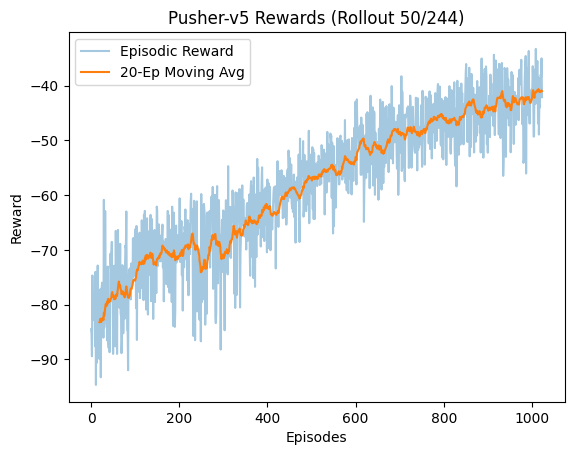

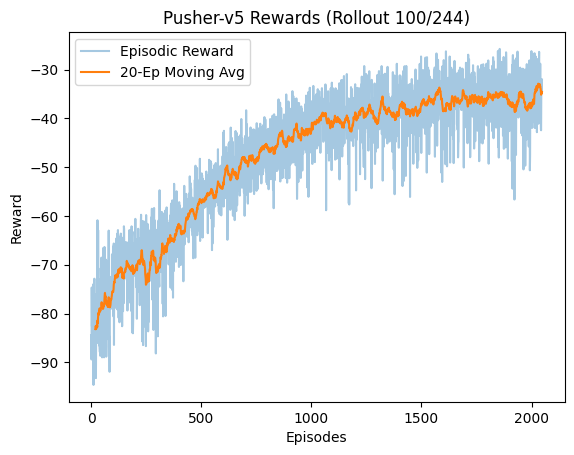

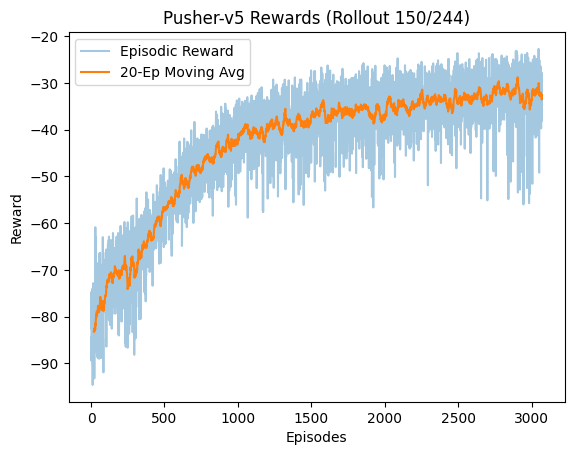

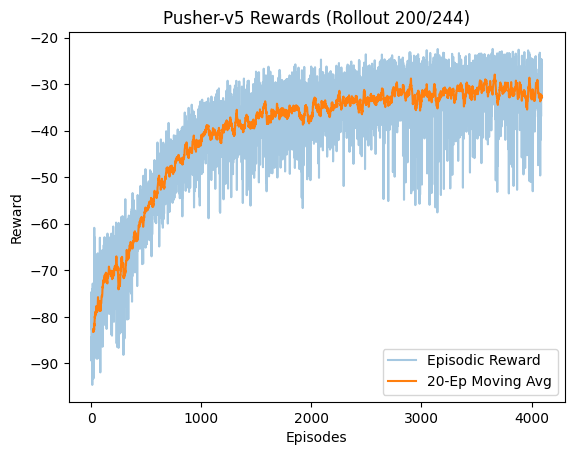

/usr/local/lib/python3.13/dist-packages/gymnasium/wrappers/rendering.py:298: UserWarning: WARN: Overwriting existing videos at /content/videos/baseline_ppo folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


[baseline_ppo] Eval Mean Reward (3 eps): -27.36


In [ ]:
#Baseline PPO
run_experiment("baseline_ppo")

### No Surrogate Clip

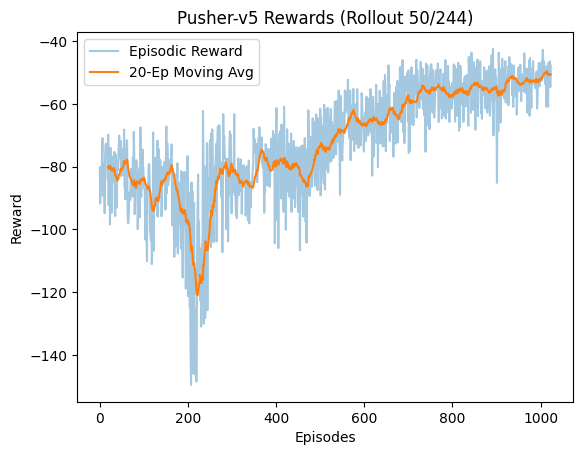

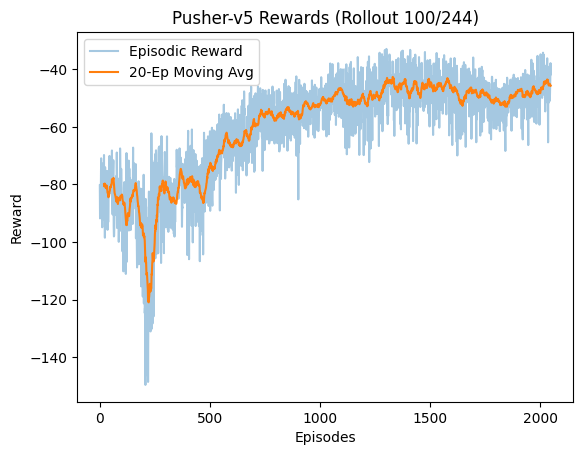

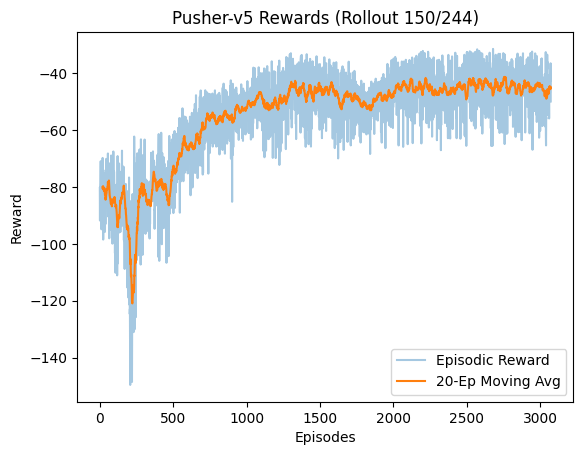

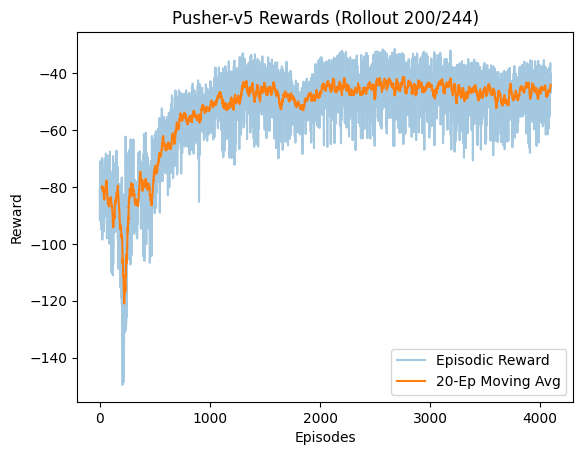

[no_clip_ppo] Eval Mean Reward (3 eps): -53.36


In [ ]:
#No Surrogate Clipping (Unclipped Policy Gradient)
run_experiment("no_clip_ppo", cur_clip_coef=100.0)

### No Advantage Normalisation

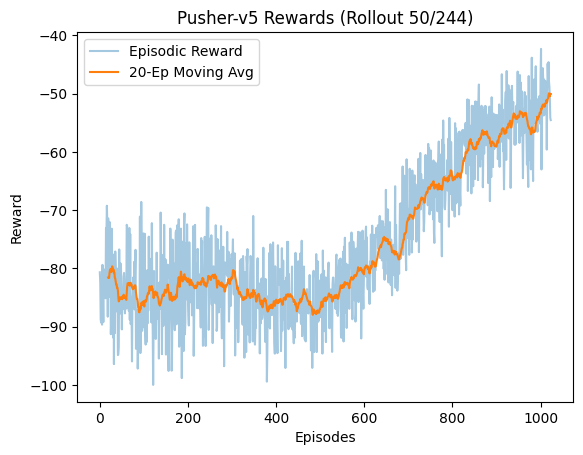

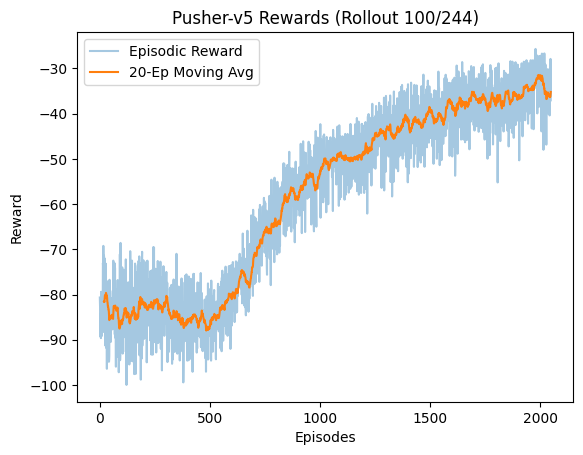

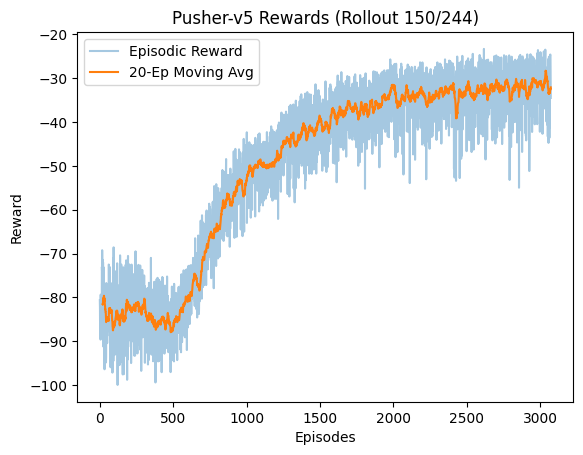

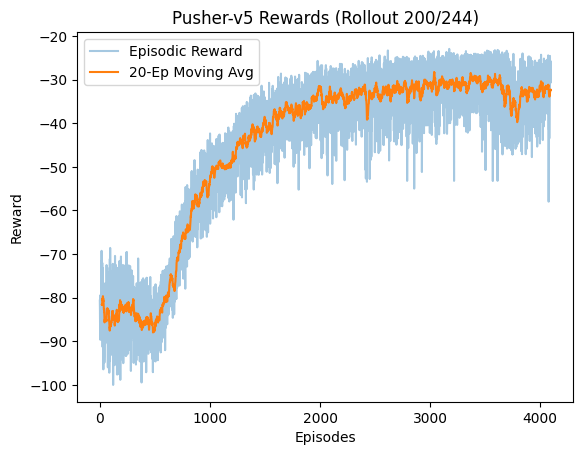

[no_adv_norm_ppo] Eval Mean Reward (3 eps): -33.38


In [ ]:
#No Advantage Normalization
run_experiment("no_adv_norm_ppo", use_adv_norm=False)

### No Observation Normalization

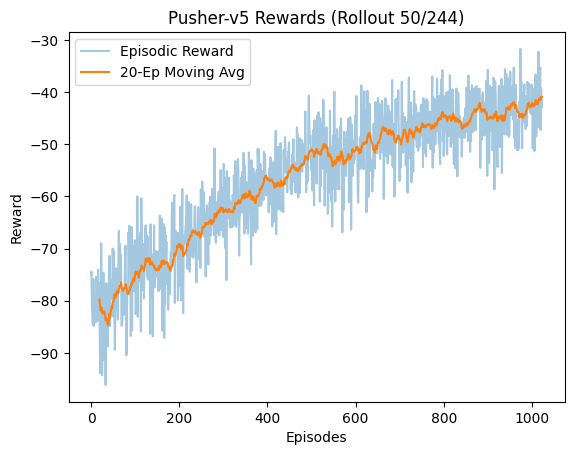

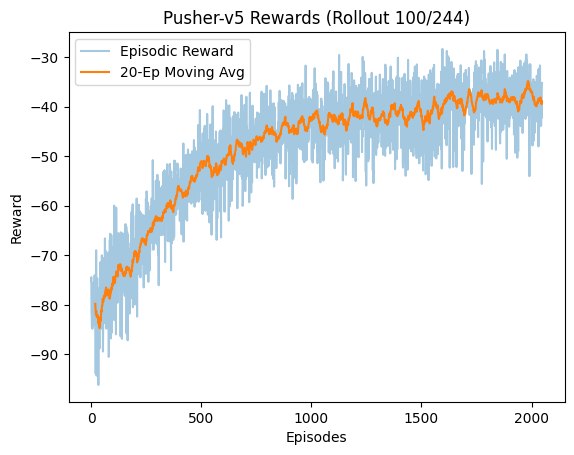

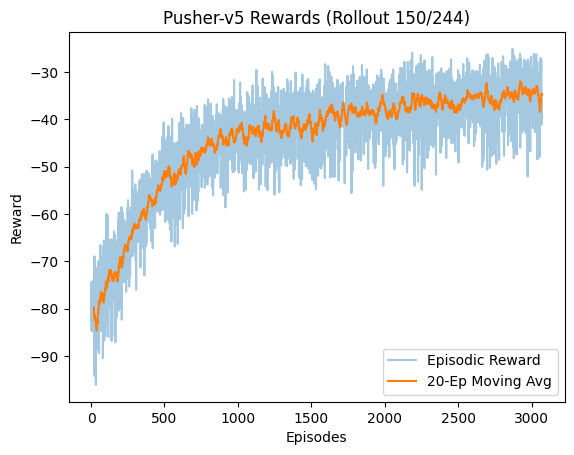

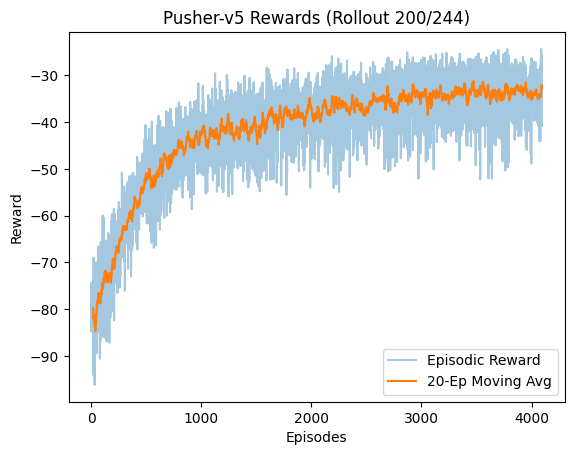

/usr/local/lib/python3.13/dist-packages/gymnasium/wrappers/rendering.py:298: UserWarning: WARN: Overwriting existing videos at /content/videos/no_obs_norm_ppo folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


[no_obs_norm_ppo] Eval Mean Reward (3 eps): -34.99


In [ ]:
#No Observation Normalization
run_experiment("no_obs_norm_ppo", use_obs_norm=False)

### No Orthogonal Initialization

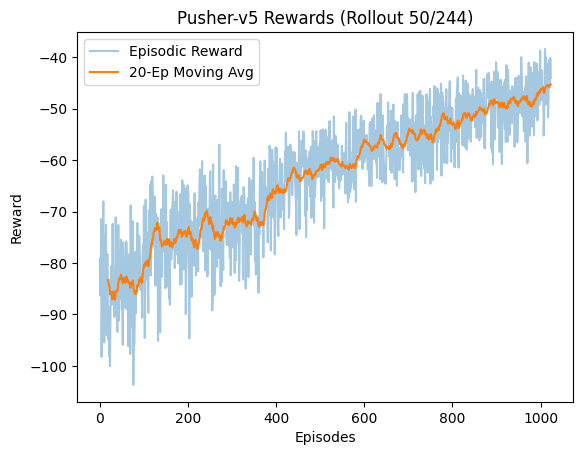

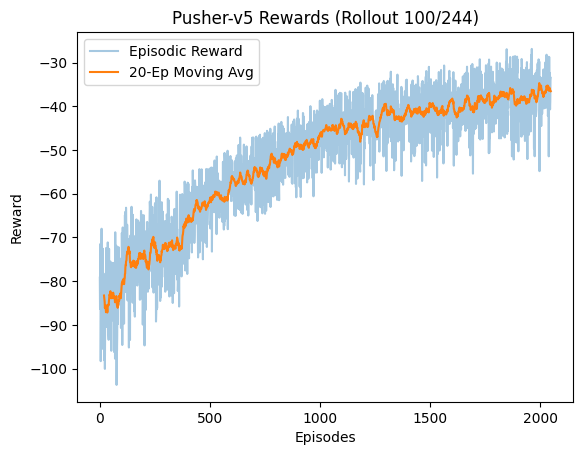

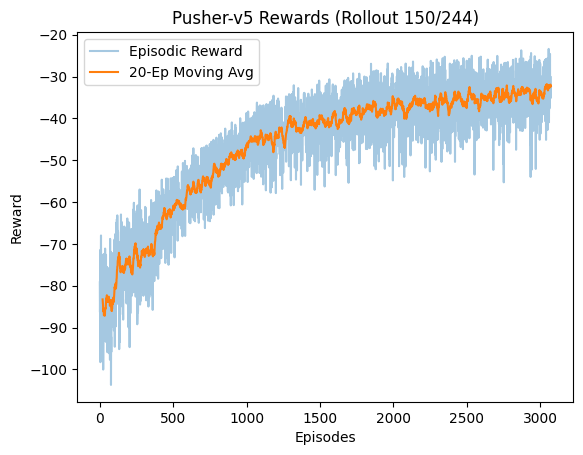

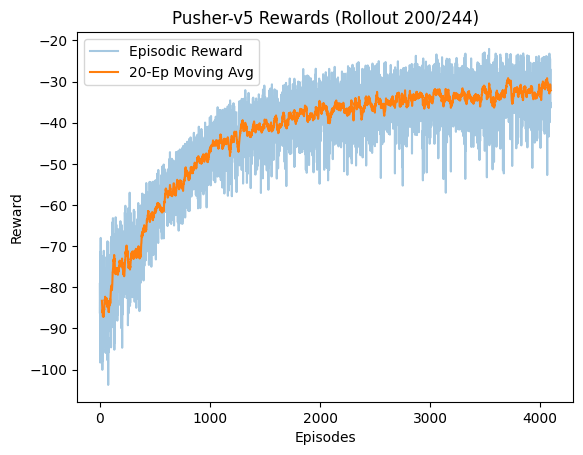

[no_ortho_init_ppo] Eval Mean Reward (3 eps): -35.59


In [ ]:
#No Orthogonal Initialization
run_experiment("no_ortho_init_ppo", use_ortho_init=False)

### Two Timescales

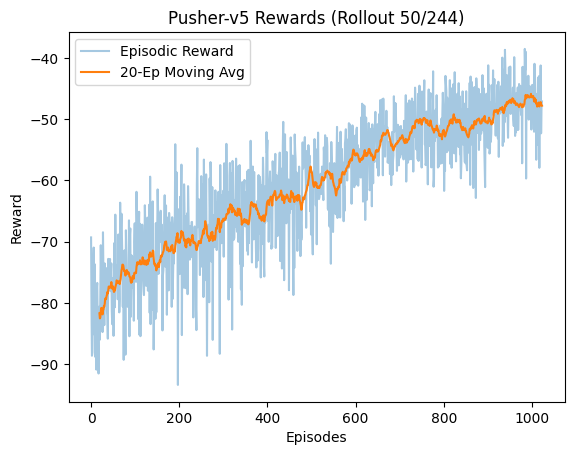

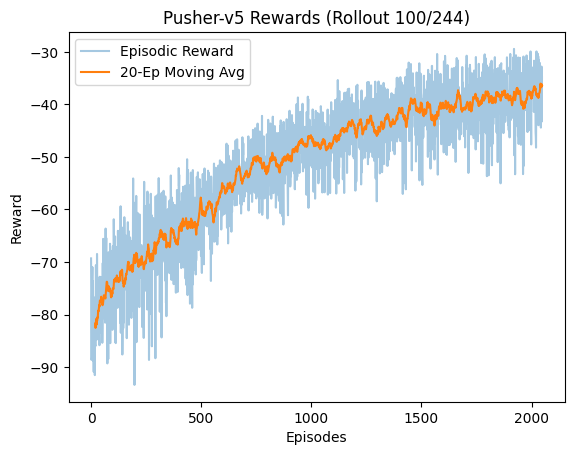

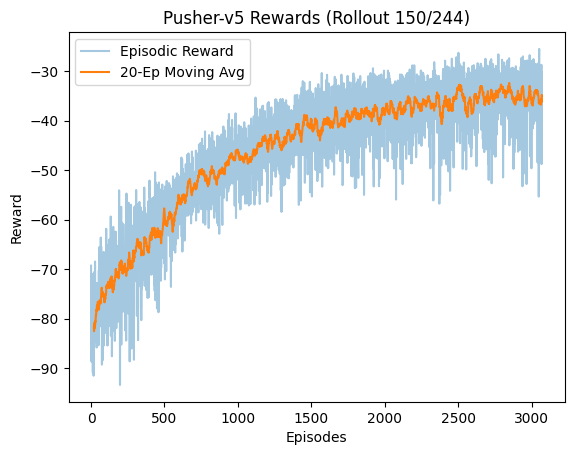

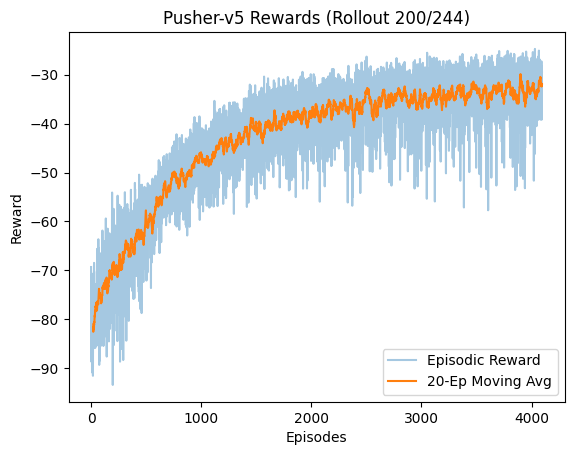

/usr/local/lib/python3.13/dist-packages/gymnasium/wrappers/rendering.py:298: UserWarning: WARN: Overwriting existing videos at /content/videos/two_timescale_ppo folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


[two_timescale_ppo] Eval Mean Reward (3 eps): -29.26


In [ ]:
#Two-Timescale Robbins-Monro PPO
run_experiment("two_timescale_ppo", two_timescale=True)

### With Reward Normalisation

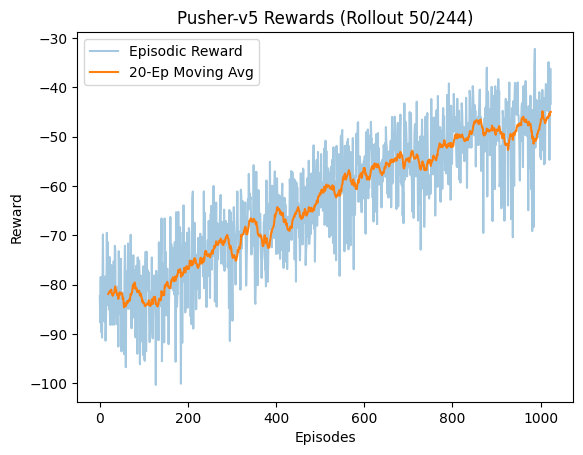

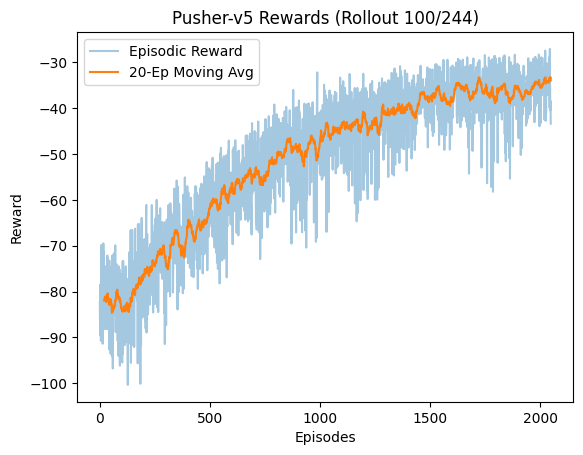

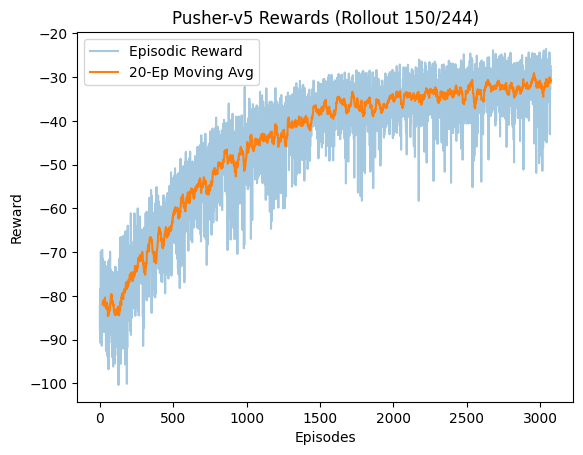

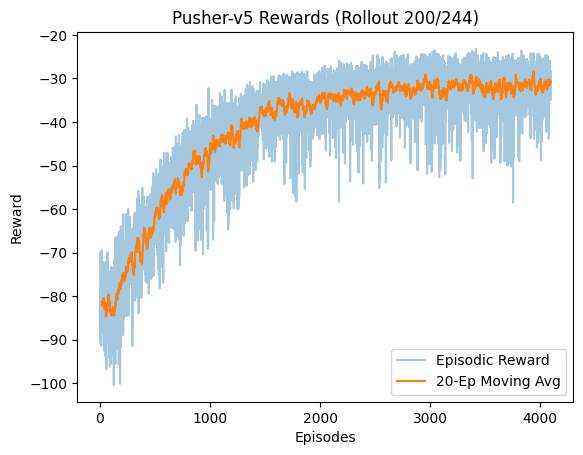

[reward_norm_ppo] Eval Mean Reward (3 eps): -23.93


In [ ]:
#Reward Normalization (Return-Std Scaling)
run_experiment("reward_norm_ppo", use_reward_norm=True)

### Results

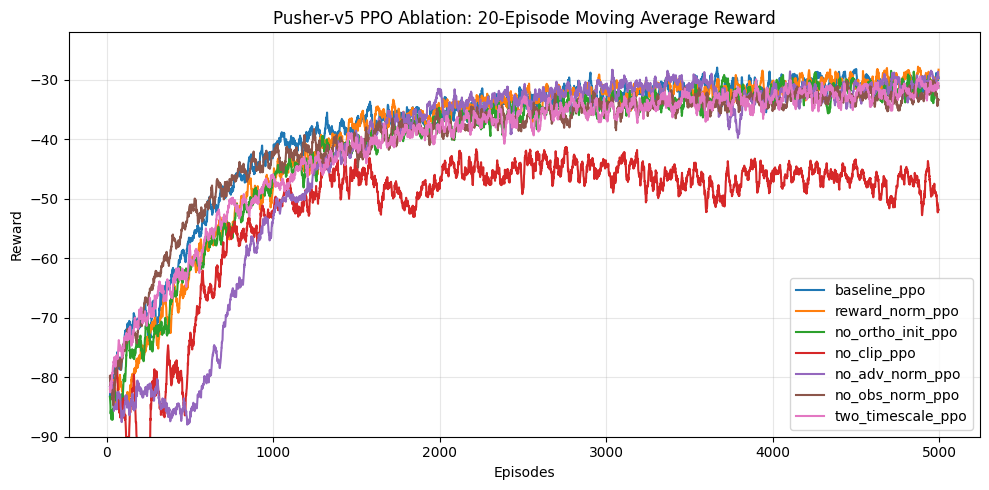

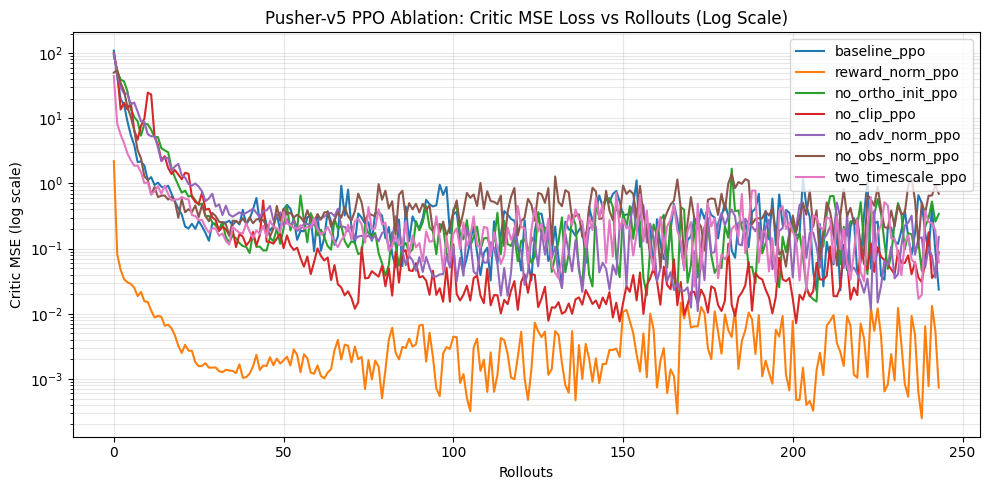

Run Name               | Last 100 Train Eps | Eval Mean (3 Eps)
---------------------------------------------------------------
baseline_ppo           |             -30.60 |            -27.36
reward_norm_ppo        |             -29.68 |            -23.93
no_ortho_init_ppo      |             -31.14 |            -35.59
no_clip_ppo            |             -48.31 |            -53.36
no_adv_norm_ppo        |             -29.97 |            -33.38
no_obs_norm_ppo        |             -31.96 |            -34.99
two_timescale_ppo      |             -31.35 |            -29.26


In [ ]:
#20-Episode Moving Average Reward
plt.figure(figsize=(10, 5))
for run_name, data in results.items():
  y = np.array(data["rewards"])
  if len(y) >= 20:
    ma = np.convolve(y, np.ones(20) / 20, mode="valid")
    plt.plot(np.arange(19, len(y)), ma, label=run_name)
plt.ylim(-90, -22)  # prevents unclipped/diverged runs from squashing the main curves
plt.title("Pusher-v5 PPO Ablation: 20-Episode Moving Average Reward")
plt.xlabel("Episodes")
plt.ylabel("Reward")
plt.grid(True, alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("pusher_v5_reward_ablation.png", dpi=150)
plt.show()

#Critic MSE Loss vs Rollouts(Log Scale)
plt.figure(figsize=(10, 5))
for run_name, data in results.items():
  plt.plot(data["critic_mses"], label=run_name)
plt.yscale("log")
plt.title("Pusher-v5 PPO Ablation: Critic MSE Loss vs Rollouts (Log Scale)")
plt.xlabel("Rollouts")
plt.ylabel("Critic MSE (log scale)")
plt.grid(True, which="both", alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig("pusher_v5_critic_mse_ablation.png", dpi=150)
plt.show()

#Summary
print(f"{'Run Name':<22}|{'Last 100 Train Eps':>18}|{'Eval Mean (3 Eps)':>17}")
print("-"*63)
for run_name, data in results.items():
  train_tail=np.mean(data["rewards"][-100:])
  eval_mean=np.mean(data["eval_rewards"])
  print(f"{run_name:<22}|{train_tail:>18.2f}|{eval_mean:>17.2f}")

In [ ]:
import gdown
import zipfile
import os

# Download directly using your File ID (no URL needed)
gdown.download(id='1-tBpk_WyUNcR2z4ngrjxWQWBKiLAiY6e', output='downloaded_files.zip', quiet=False)

# Extract the files
with zipfile.ZipFile('downloaded_files.zip', 'r') as zip_ref:
    zip_ref.extractall('unzipped_data')

# Show the extracted files
print("\nExtraction complete! Here are your files:")
for root, dirs, files in os.walk('unzipped_data'):
    for file in files:
        print(os.path.join(root, file))


Downloading...
From: https://drive.google.com/uc?id=1-tBpk_WyUNcR2z4ngrjxWQWBKiLAiY6e
To: /content/downloaded_files.zip
100%|██████████| 1.01M/1.01M [00:00<00:00, 43.8MB/s]


Extraction complete! Here are your files:
unzipped_data/pusher_v5_critic_mse_ablation.png
unzipped_data/pusher_v5_reward_ablation.png
unzipped_data/videos/two_timescale_ppo/two_timescale_ppo-episode-0.mp4
unzipped_data/videos/two_timescale_ppo/two_timescale_ppo-episode-2.mp4
unzipped_data/videos/two_timescale_ppo/two_timescale_ppo-episode-1.mp4
unzipped_data/videos/baseline_ppo/baseline_ppo-episode-2.mp4
unzipped_data/videos/baseline_ppo/baseline_ppo-episode-0.mp4
unzipped_data/videos/baseline_ppo/baseline_ppo-episode-1.mp4
unzipped_data/videos/reward_norm_ppo/reward_norm_ppo-episode-1.mp4
unzipped_data/videos/reward_norm_ppo/reward_norm_ppo-episode-2.mp4
unzipped_data/videos/reward_norm_ppo/reward_norm_ppo-episode-0.mp4
unzipped_data/videos/no_adv_norm_ppo/no_adv_norm_ppo-episode-1.mp4
unzipped_data/videos/no_adv_norm_ppo/no_adv_norm_ppo-episode-0.mp4
unzipped_data/videos/no_adv_norm_ppo/no_adv_norm_ppo-episode-2.mp4
unzipped_data/videos/no_clip_ppo/no_clip_ppo-episode-0.mp4
unzipped

###Saving to my device

In [ ]:
!zip -r pusher_v5_ablation_outputs.zip videos/ *.png

from google.colab import files
files.download("pusher_v5_ablation_outputs.zip")

  adding: videos/ (stored 0%)
  adding: videos/no_obs_norm_ppo/ (stored 0%)
  adding: videos/no_obs_norm_ppo/no_obs_norm_ppo-episode-2.mp4 (deflated 12%)
  adding: videos/no_obs_norm_ppo/no_obs_norm_ppo-episode-0.mp4 (deflated 9%)
  adding: videos/no_obs_norm_ppo/no_obs_norm_ppo-episode-1.mp4 (deflated 9%)
  adding: videos/no_ortho_init_ppo/ (stored 0%)
  adding: videos/no_ortho_init_ppo/no_ortho_init_ppo-episode-2.mp4 (deflated 11%)
  adding: videos/no_ortho_init_ppo/no_ortho_init_ppo-episode-0.mp4 (deflated 9%)
  adding: videos/no_ortho_init_ppo/no_ortho_init_ppo-episode-1.mp4 (deflated 9%)
  adding: videos/two_timescale_ppo/ (stored 0%)
  adding: videos/two_timescale_ppo/two_timescale_ppo-episode-2.mp4 (deflated 10%)
  adding: videos/two_timescale_ppo/two_timescale_ppo-episode-0.mp4 (deflated 12%)
  adding: videos/two_timescale_ppo/two_timescale_ppo-episode-1.mp4 (deflated 10%)
  adding: videos/baseline_ppo/ (stored 0%)
  adding: videos/baseline_ppo/baseline_ppo-episode-2.mp4 (defla

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>